In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import r2_score, accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_excel("/content/cancer patient data sets.xlsx")

In [3]:
df

,Patient Id,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,...,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
0,P1,33,1,2,4,5,4,3,2,2,...,3,4,2,2,3,1,2,3,4,Low
1,P10,17,1,3,1,5,3,4,2,2,...,1,3,7,8,6,2,1,7,2,Medium
2,P100,35,1,4,5,6,5,5,4,6,...,8,7,9,2,1,4,6,7,2,High
3,P1000,37,1,7,7,7,7,6,7,7,...,4,2,3,1,4,5,6,7,5,High
4,P101,46,1,6,8,7,7,7,6,7,...,3,2,4,1,4,2,4,2,3,High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,P995,44,1,6,7,7,7,7,6,7,...,5,3,2,7,8,2,4,5,3,High
996,P996,37,2,6,8,7,7,7,6,7,...,9,6,5,7,2,4,3,1,4,High
997,P997,25,2,4,5,6,5,5,4,6,...,8,7,9,2,1,4,6,7,2,High
998,P998,18,2,6,8,7,7,7,6,7,...,3,2,4,1,4,2,4,2,3,High


In [4]:
df.sample(5)

,Patient Id,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,...,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
264,P336,48,1,4,2,3,2,1,2,3,...,2,6,1,2,4,2,1,2,3,Low
491,P540,35,1,1,3,2,4,2,6,2,...,4,2,2,2,3,2,1,2,4,Low
345,P409,39,1,4,5,6,6,5,4,6,...,5,3,2,4,3,1,7,5,6,Medium
184,P264,33,1,3,2,4,2,3,2,3,...,4,5,6,5,5,4,6,5,4,Medium
827,P843,18,2,3,2,1,3,2,1,3,...,2,2,1,3,4,4,1,4,1,Low


In [5]:
df.head()

,Patient Id,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,...,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
0,P1,33,1,2,4,5,4,3,2,2,...,3,4,2,2,3,1,2,3,4,Low
1,P10,17,1,3,1,5,3,4,2,2,...,1,3,7,8,6,2,1,7,2,Medium
2,P100,35,1,4,5,6,5,5,4,6,...,8,7,9,2,1,4,6,7,2,High
3,P1000,37,1,7,7,7,7,6,7,7,...,4,2,3,1,4,5,6,7,5,High
4,P101,46,1,6,8,7,7,7,6,7,...,3,2,4,1,4,2,4,2,3,High


In [6]:
df.tail()

,Patient Id,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,...,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
995,P995,44,1,6,7,7,7,7,6,7,...,5,3,2,7,8,2,4,5,3,High
996,P996,37,2,6,8,7,7,7,6,7,...,9,6,5,7,2,4,3,1,4,High
997,P997,25,2,4,5,6,5,5,4,6,...,8,7,9,2,1,4,6,7,2,High
998,P998,18,2,6,8,7,7,7,6,7,...,3,2,4,1,4,2,4,2,3,High
999,P999,47,1,6,5,6,5,5,4,6,...,8,7,9,2,1,4,6,7,2,High


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Patient Id                1000 non-null   object
 1   Age                       1000 non-null   int64 
 2   Gender                    1000 non-null   int64 
 3   Air Pollution             1000 non-null   int64 
 4   Alcohol use               1000 non-null   int64 
 5   Dust Allergy              1000 non-null   int64 
 6   OccuPational Hazards      1000 non-null   int64 
 7   Genetic Risk              1000 non-null   int64 
 8   chronic Lung Disease      1000 non-null   int64 
 9   Balanced Diet             1000 non-null   int64 
 10  Obesity                   1000 non-null   int64 
 11  Smoking                   1000 non-null   int64 
 12  Passive Smoker            1000 non-null   int64 
 13  Chest Pain                1000 non-null   int64 
 14  Coughing of Blood        

In [8]:
df.isnull().sum()

,0
Patient Id,0
Age,0
Gender,0
Air Pollution,0
Alcohol use,0
Dust Allergy,0
OccuPational Hazards,0
Genetic Risk,0
chronic Lung Disease,0
Balanced Diet,0


In [9]:
df.dtypes

,0
Patient Id,object
Age,int64
Gender,int64
Air Pollution,int64
Alcohol use,int64
Dust Allergy,int64
OccuPational Hazards,int64
Genetic Risk,int64
chronic Lung Disease,int64
Balanced Diet,int64


In [10]:
df.shape

(1000, 25)

In [11]:
df.columns

Index(['Patient Id', 'Age', 'Gender', 'Air Pollution', 'Alcohol use',
       'Dust Allergy', 'OccuPational Hazards', 'Genetic Risk',
       'chronic Lung Disease', 'Balanced Diet', 'Obesity', 'Smoking',
       'Passive Smoker', 'Chest Pain', 'Coughing of Blood', 'Fatigue',
       'Weight Loss', 'Shortness of Breath', 'Wheezing',
       'Swallowing Difficulty', 'Clubbing of Finger Nails', 'Frequent Cold',
       'Dry Cough', 'Snoring', 'Level'],
      dtype='object')

In [12]:
df.nunique()

,0
Patient Id,1000
Age,40
Gender,2
Air Pollution,8
Alcohol use,8
Dust Allergy,8
OccuPational Hazards,8
Genetic Risk,7
chronic Lung Disease,7
Balanced Diet,7


In [13]:
df.Level.value_counts()

,count
Level,
High,365
Medium,332
Low,303


In [14]:
df= df.drop(['Patient Id'],axis= 1)
df.head()

,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,Obesity,...,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
0,33,1,2,4,5,4,3,2,2,4,...,3,4,2,2,3,1,2,3,4,Low
1,17,1,3,1,5,3,4,2,2,2,...,1,3,7,8,6,2,1,7,2,Medium
2,35,1,4,5,6,5,5,4,6,7,...,8,7,9,2,1,4,6,7,2,High
3,37,1,7,7,7,7,6,7,7,7,...,4,2,3,1,4,5,6,7,5,High
4,46,1,6,8,7,7,7,6,7,7,...,3,2,4,1,4,2,4,2,3,High


In [15]:
df.dtypes

,0
Age,int64
Gender,int64
Air Pollution,int64
Alcohol use,int64
Dust Allergy,int64
OccuPational Hazards,int64
Genetic Risk,int64
chronic Lung Disease,int64
Balanced Diet,int64
Obesity,int64


In [16]:
encoder= LabelEncoder()
encoded_level = encoder.fit_transform(df['Level'])



In [17]:
encoded_level

array([1, 2, 0, 0, 0, 0, 1, 1, 2, 2, 0, 0, 2, 0, 1, 2, 2, 0, 0, 2, 0, 0,
       0, 0, 0, 2, 2, 2, 0, 2, 0, 0, 2, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 2, 2, 2,
       2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 0,
       0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 2, 0, 0, 0, 1, 1, 2, 2, 0, 0, 2, 0, 1, 2, 2, 0, 0, 2, 0,
       0, 0, 0, 2, 2, 2, 2, 0, 2, 0, 0, 2, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 2,
       2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 2, 1, 0, 0, 0, 1, 1, 2, 2, 0, 0, 2, 1, 1, 2, 2, 0, 0, 2,
       0, 0, 0, 0, 1, 2, 2, 2, 0, 2, 0, 0, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2,
       2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,

In [18]:
encoded_level_df = pd.DataFrame(encoded_level)

In [19]:
df = df.drop('Level', axis =1)
df - pd.concat([df, encoded_level_df], axis = 1)

,0,Age,Air Pollution,Alcohol use,Balanced Diet,Chest Pain,Clubbing of Finger Nails,Coughing of Blood,Dry Cough,Dust Allergy,...,Obesity,OccuPational Hazards,Passive Smoker,Shortness of Breath,Smoking,Snoring,Swallowing Difficulty,Weight Loss,Wheezing,chronic Lung Disease
0,NaN,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,NaN,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,NaN,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,NaN,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,NaN,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,NaN,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
996,NaN,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
997,NaN,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
998,NaN,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


<Axes: xlabel='Age', ylabel='Density'>

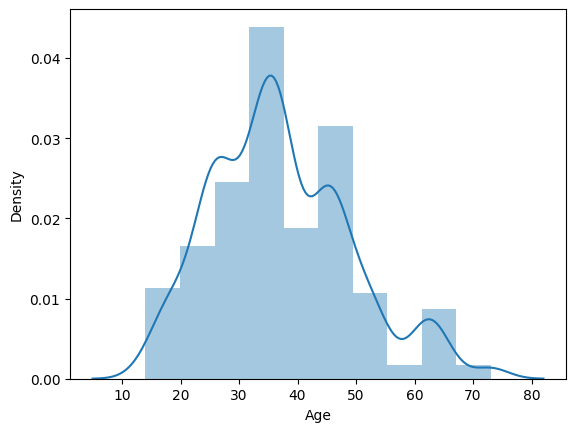

In [20]:
sns.distplot(df['Age'], bins=10)

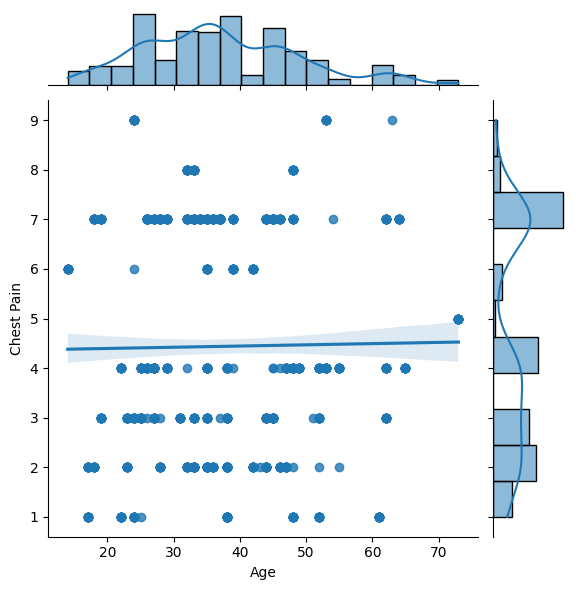

In [21]:
sns.jointplot(x='Age', y='Chest Pain', data=df, kind='reg')

<Axes: >

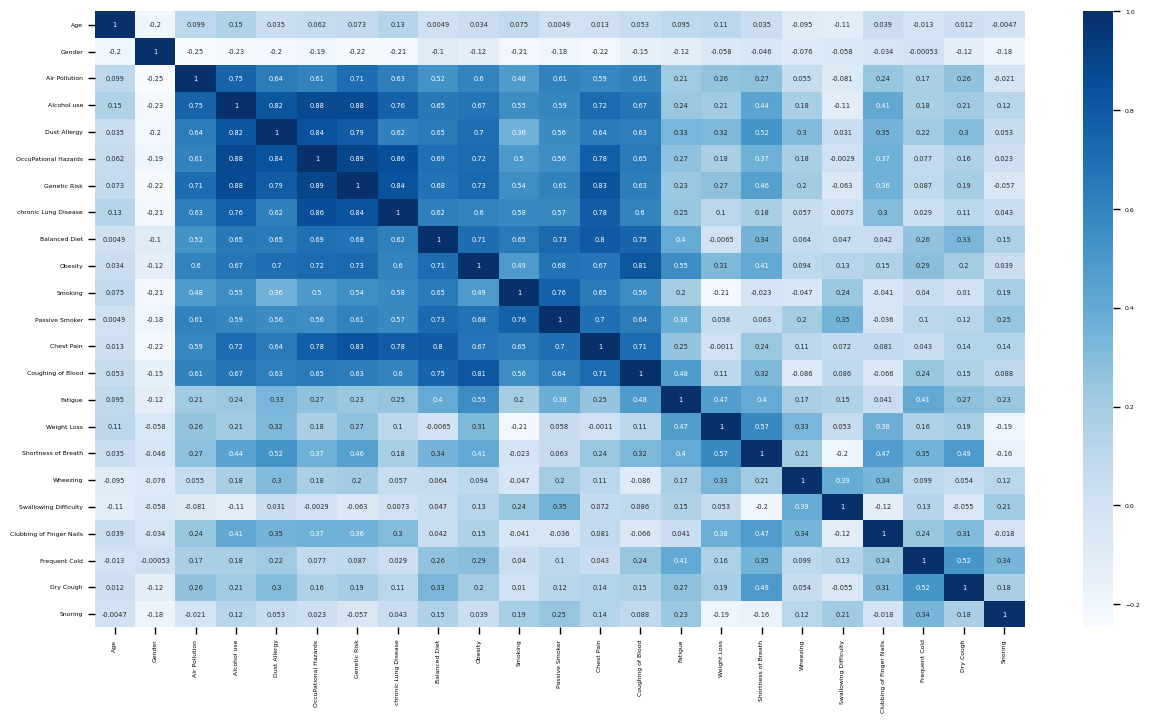

In [22]:
plt.figure(figsize=(15,8))
sns.set_context('paper', font_scale=0.5)

df_mx = df.corr()
sns.heatmap(df_mx, annot=True, cmap='Blues')

<Figure size 1500x800 with 0 Axes>

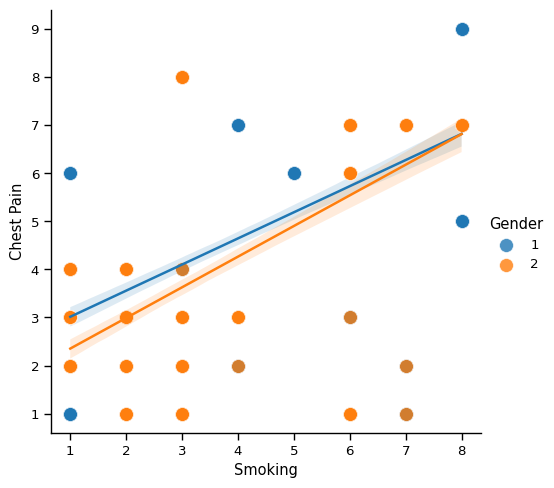

In [23]:
plt.figure(figsize=(15,8))
sns.set_context('paper', font_scale=1.1)
sns.lmplot(x='Smoking', y='Chest Pain', hue='Gender', data=df, scatter_kws={'s':100, 'linewidths': 0.5,'edgecolor':'w' })

<Figure size 1000x600 with 0 Axes>

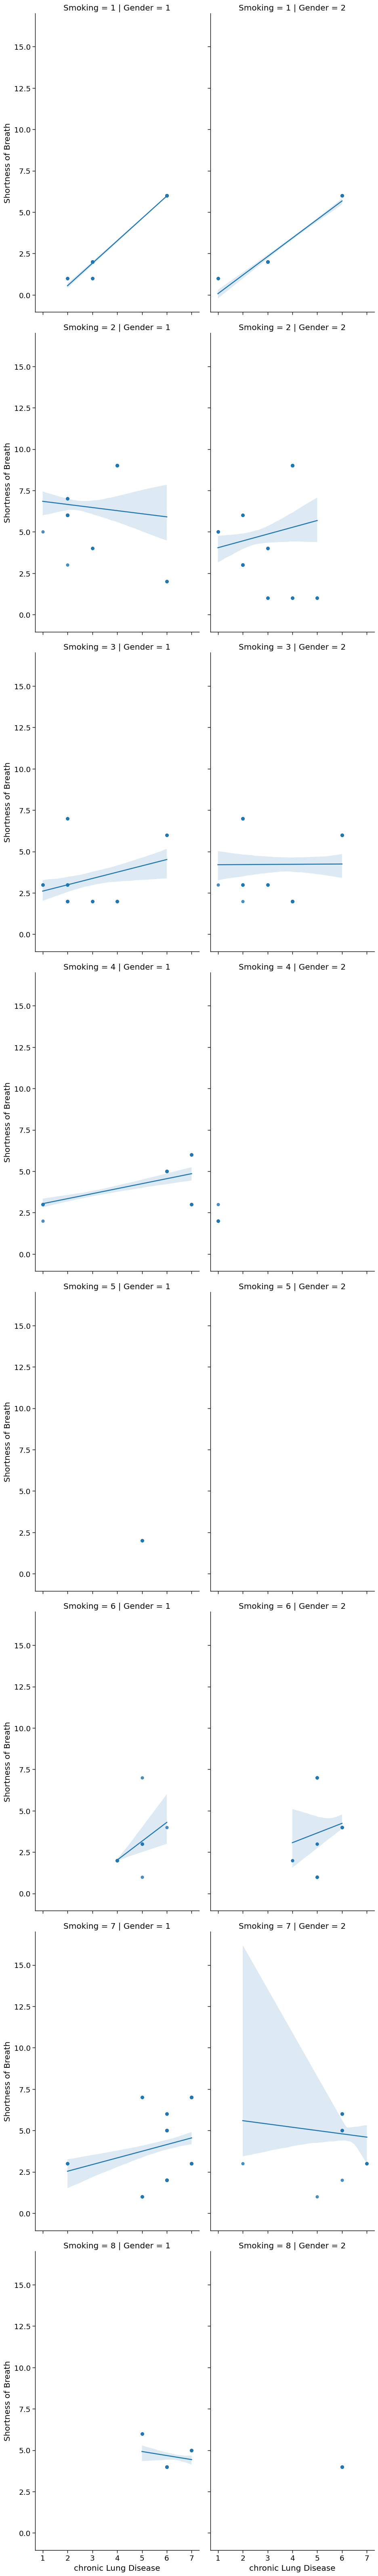

In [24]:
plt.figure(figsize=(10,6))
sns.set_context('paper', font_scale=1.5)
sns.lmplot(x='chronic Lung Disease', y='Shortness of Breath', col='Gender', row='Smoking', data=df, height=8, aspect=0.6)

# Exploratory Data Analysis — Question-Driven Visualisations

The following visualisations answer specific questions about the dataset. Each chart includes a clear title, axis labels, and a short interpretation. The visualisation section reloads the original dataset so the `Level` target remains available after the preprocessing cells above.

In [25]:
# Reload the original data for EDA so that the target column 'Level' is available.
viz_df = pd.read_excel('/content/cancer patient data sets.xlsx')
viz_df = viz_df.drop(columns=['Patient Id'])
viz_df.head()


,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,Obesity,...,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
0,33,1,2,4,5,4,3,2,2,4,...,3,4,2,2,3,1,2,3,4,Low
1,17,1,3,1,5,3,4,2,2,2,...,1,3,7,8,6,2,1,7,2,Medium
2,35,1,4,5,6,5,5,4,6,7,...,8,7,9,2,1,4,6,7,2,High
3,37,1,7,7,7,7,6,7,7,7,...,4,2,3,1,4,5,6,7,5,High
4,46,1,6,8,7,7,7,6,7,7,...,3,2,4,1,4,2,4,2,3,High


## Question 1: How is the age of patients distributed?

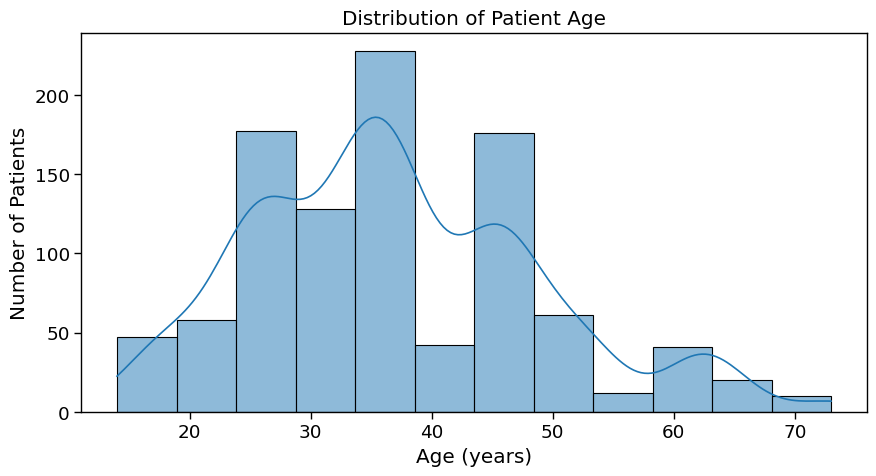

In [26]:
plt.figure(figsize=(9, 5))
sns.histplot(viz_df['Age'], bins=12, kde=True)
plt.title('Distribution of Patient Age')
plt.xlabel('Age (years)')
plt.ylabel('Number of Patients')
plt.tight_layout()
plt.show()


**Interpretation:** The patients cover a broad adult age range rather than being concentrated in a single age group. Age has only a weak monotonic relationship with `Level` in this dataset, so age alone does not explain the risk-level differences.

## Question 2: How balanced are the three cancer-risk levels?

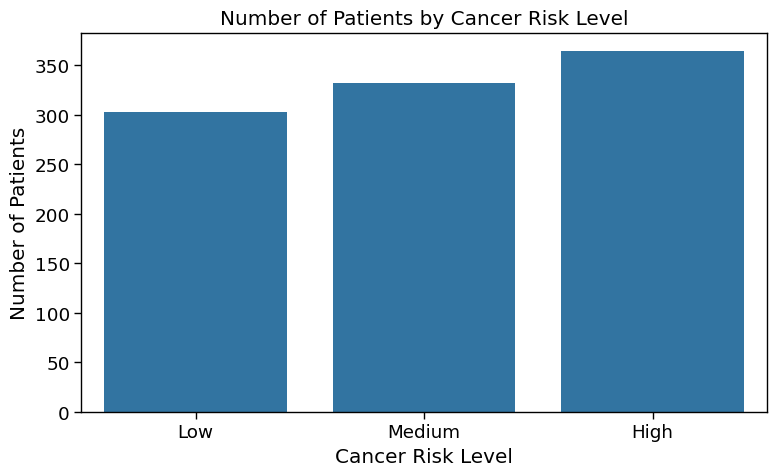

In [27]:
plt.figure(figsize=(8, 5))
level_order = ['Low', 'Medium', 'High']
sns.countplot(data=viz_df, x='Level', order=level_order)
plt.title('Number of Patients by Cancer Risk Level')
plt.xlabel('Cancer Risk Level')
plt.ylabel('Number of Patients')
plt.tight_layout()
plt.show()


**Interpretation:** The classes are reasonably balanced: Low has 303 patients, Medium has 332, and High has 365. The High group is the largest, but no single class dominates the dataset.

## Question 3: Does obesity severity differ across cancer-risk levels?

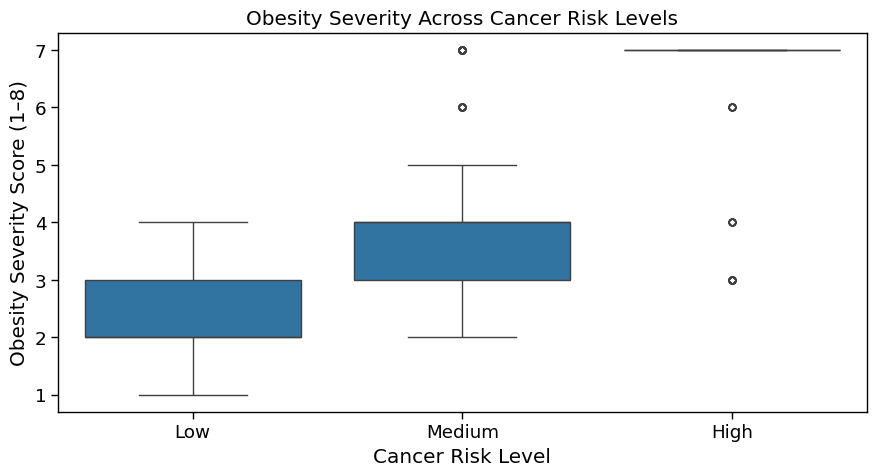

In [28]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=viz_df, x='Level', y='Obesity', order=level_order)
plt.title('Obesity Severity Across Cancer Risk Levels')
plt.xlabel('Cancer Risk Level')
plt.ylabel('Obesity Severity Score (1–8)')
plt.tight_layout()
plt.show()


**Interpretation:** Obesity scores are substantially higher in the Medium and High groups than in the Low group, showing a strong association with the target level. In the dataset, Obesity has the strongest Spearman correlation with `Level` (about 0.815), although this is an association rather than proof of causation.

## Question 4: How do major environmental and lifestyle factors vary by cancer-risk level?

<Figure size 1200x600 with 0 Axes>

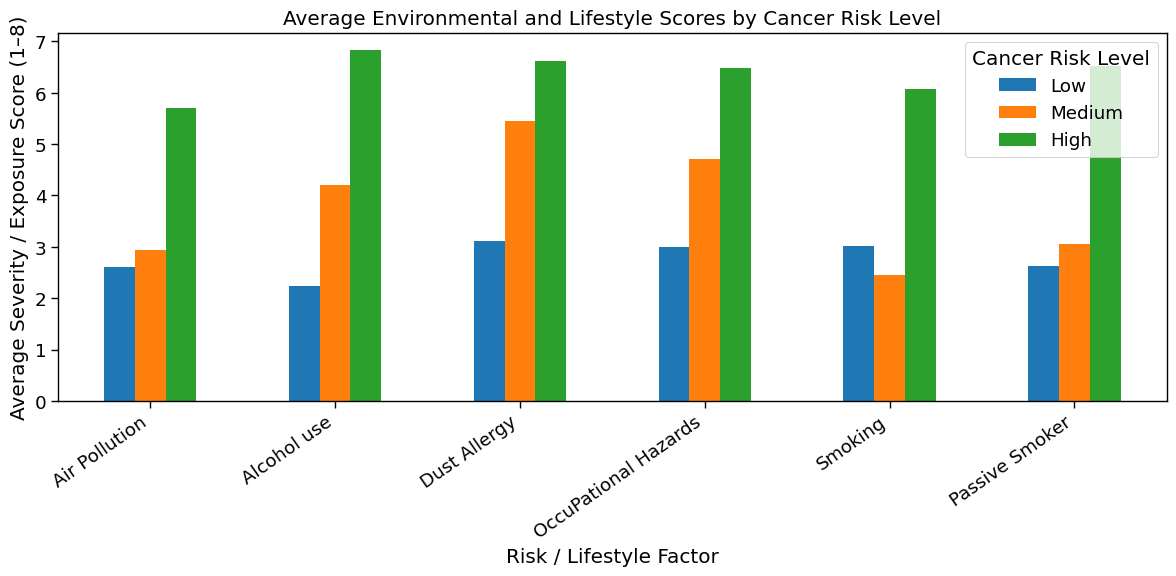

In [29]:
factors = ['Air Pollution', 'Alcohol use', 'Dust Allergy', 'OccuPational Hazards', 'Smoking', 'Passive Smoker']
factor_means = viz_df.groupby('Level')[factors].mean().reindex(level_order)

plt.figure(figsize=(12, 6))
factor_means.T.plot(kind='bar', figsize=(12, 6))
plt.title('Average Environmental and Lifestyle Scores by Cancer Risk Level')
plt.xlabel('Risk / Lifestyle Factor')
plt.ylabel('Average Severity / Exposure Score (1–8)')
plt.xticks(rotation=35, ha='right')
plt.legend(title='Cancer Risk Level')
plt.tight_layout()
plt.show()


**Interpretation:** The average exposure and lifestyle scores generally increase from Low toward High risk, particularly for air pollution, alcohol use, dust allergy, and passive smoking. This pattern suggests that several environmental and lifestyle variables move together with the recorded risk level.

## Question 5: Which symptoms show the largest differences between risk levels?

<Figure size 1100x600 with 0 Axes>

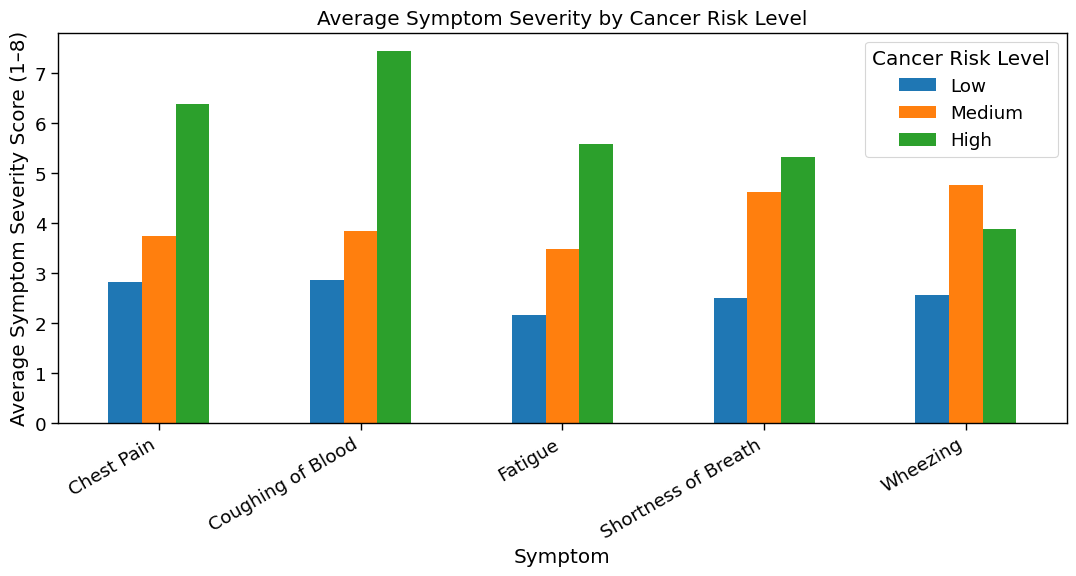

In [30]:
symptoms = ['Chest Pain', 'Coughing of Blood', 'Fatigue', 'Shortness of Breath', 'Wheezing']
symptom_means = viz_df.groupby('Level')[symptoms].mean().reindex(level_order)

plt.figure(figsize=(11, 6))
symptom_means.T.plot(kind='bar', figsize=(11, 6))
plt.title('Average Symptom Severity by Cancer Risk Level')
plt.xlabel('Symptom')
plt.ylabel('Average Symptom Severity Score (1–8)')
plt.xticks(rotation=30, ha='right')
plt.legend(title='Cancer Risk Level')
plt.tight_layout()
plt.show()


**Interpretation:** Symptom severity is generally higher in the High-risk group, with coughing of blood and chest pain showing particularly strong relationships with `Level`. This indicates that symptom variables contain useful information for distinguishing the recorded risk categories.

## Question 6: Which numerical features have the strongest relationship with cancer-risk level?

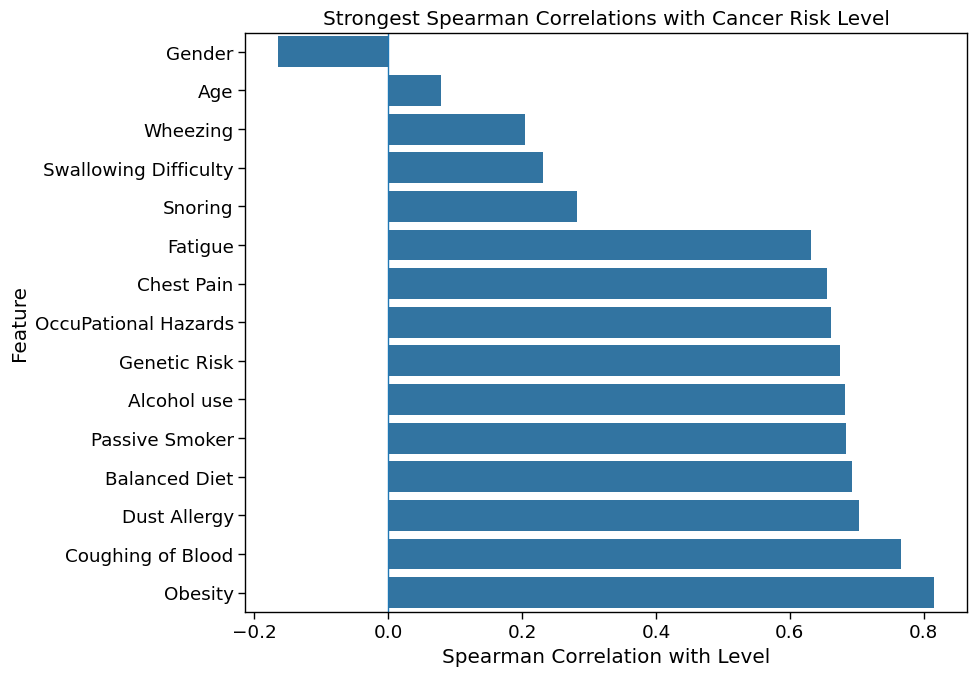

Top positive correlations:
Obesity                 0.815
Coughing of Blood       0.766
Dust Allergy            0.703
Balanced Diet           0.692
Passive Smoker          0.683
Alcohol use             0.682
Genetic Risk            0.676
OccuPational Hazards    0.661
Chest Pain              0.655
Fatigue                 0.631
dtype: float64


In [31]:
level_numeric = viz_df['Level'].map({'Low': 0, 'Medium': 1, 'High': 2})
numeric_features = viz_df.select_dtypes(include=np.number).columns
spearman_corr = viz_df[numeric_features].corrwith(level_numeric, method='spearman').sort_values()
top_features = pd.concat([spearman_corr.head(5), spearman_corr.tail(10)]).sort_values()

plt.figure(figsize=(10, 7))
sns.barplot(x=top_features.values, y=top_features.index, orient='h')
plt.title('Strongest Spearman Correlations with Cancer Risk Level')
plt.xlabel('Spearman Correlation with Level')
plt.ylabel('Feature')
plt.axvline(0, linewidth=1)
plt.tight_layout()
plt.show()

print('Top positive correlations:')
print(spearman_corr.sort_values(ascending=False).head(10).round(3))


**Interpretation:** Obesity has the strongest positive monotonic relationship with `Level` (approximately 0.815), followed by coughing of blood (approximately 0.766) and several exposure/risk variables. Correlation identifies association in this dataset; it should not be interpreted as evidence that any single feature causes cancer.

# Summary: 5 Most Interesting Findings

1. **The target classes are reasonably balanced.** The dataset contains 303 Low-risk, 332 Medium-risk, and 365 High-risk patients, so the largest class is only moderately larger than the smallest.

2. **Obesity is the strongest numerical association with the recorded risk level.** Its Spearman correlation with `Level` is approximately **0.815**, and the boxplot shows higher obesity scores in the higher-risk groups.

3. **Coughing of blood is strongly associated with risk level.** Its Spearman correlation is approximately **0.766**, and its average severity increases across the risk categories.

4. **Environmental and lifestyle factors show a consistent pattern.** Air pollution, alcohol use, dust allergy, occupational hazards, smoking, and passive smoking generally have higher average scores in the higher-risk groups.

5. **Age is much less strongly related to the target than many risk and symptom variables.** Its Spearman correlation with `Level` is only about **0.079**, indicating that age by itself is not a strong monotonic signal for the recorded risk category in this dataset.

> **Overall takeaway:** The strongest patterns in this dataset come from combinations of lifestyle, environmental exposure, and symptom-severity variables rather than age alone. These findings describe associations in this dataset and should not be interpreted as clinical or causal conclusions.